In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from pathlib import Path
from scipy.stats import chi2

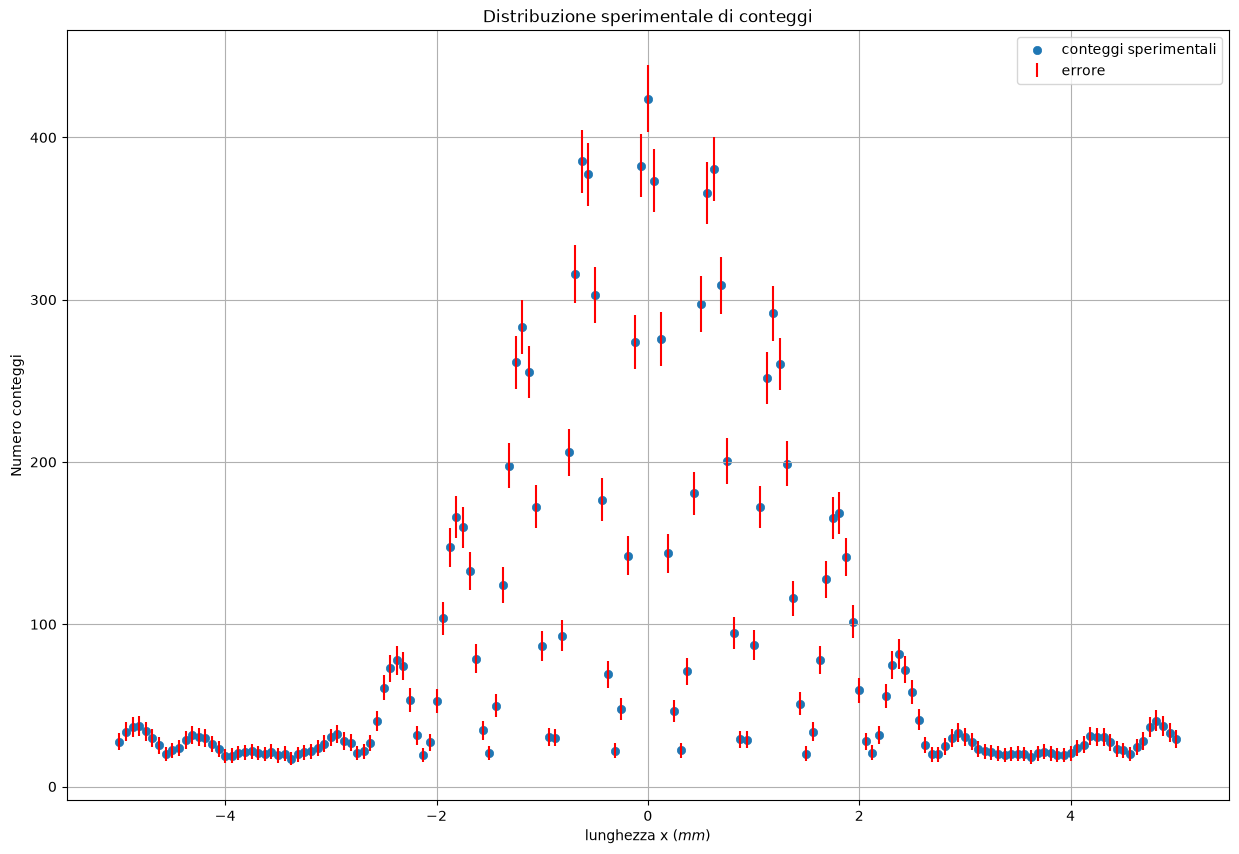

In [19]:
dati= np.genfromtxt(
    "dati_20.csv",
    delimiter=",",
    names=True
)
x=dati["x"]
y=dati["y"]
sigma_y=dati["sigma_y"]

plt.figure(figsize=(15,10))
plt.scatter(x,y,lw=0.5, label="conteggi sperimentali")
plt.errorbar(x,y,sigma_y,color="r",ls="none",lw=1.5, label="errore" )

plt.xlabel("lunghezza x ($mm$)")
plt.ylabel("Numero conteggi")
plt.title("Distribuzione sperimentale di conteggi")

plt.legend()
plt.grid(True)
plt.show()

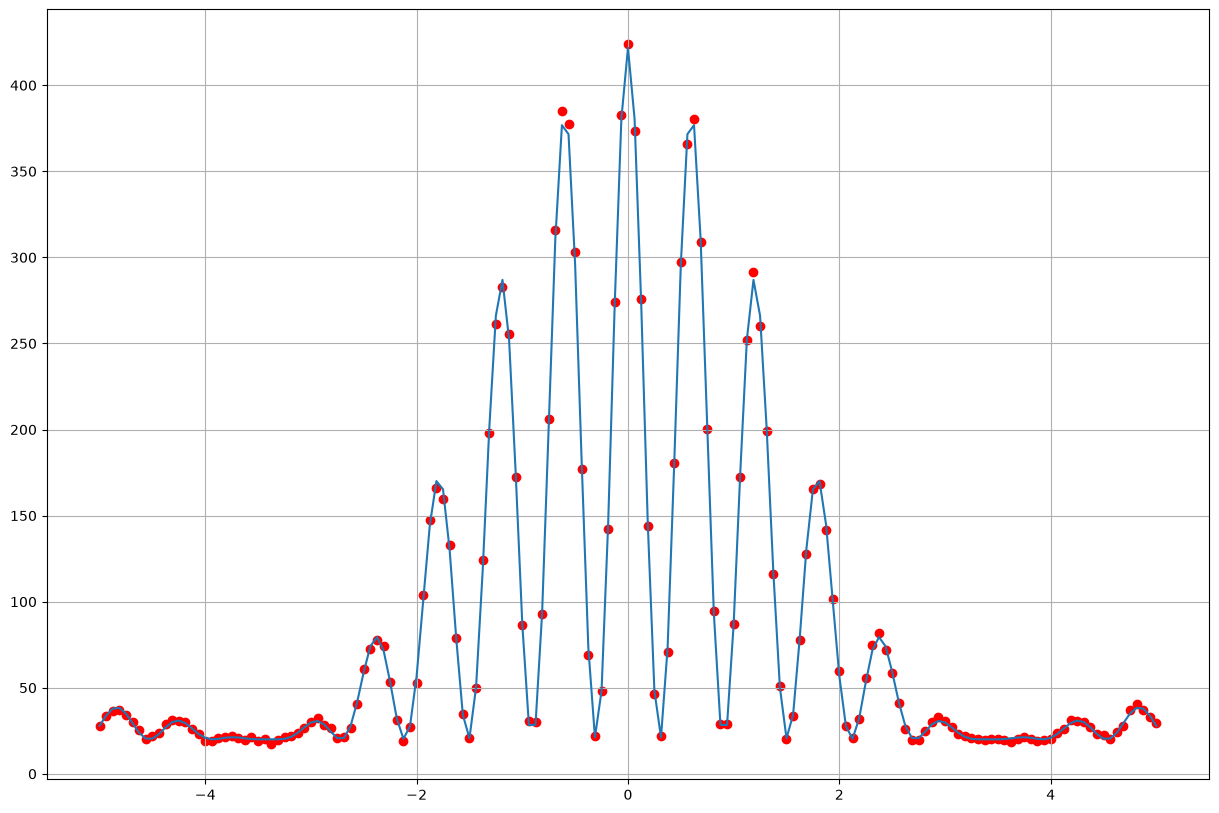

In [20]:
B_0=np.median(y)

I0_0=np.max(y)-B_0

p0=[B_0, I0_0,0.5,5.0]

lower=[0.0,0.0,0.10,1.0]
upper=[np.inf,np.inf,3.0,12.0]

def sinusoide(x,B,I0, alpha, delta):
    res= B + I0*(np.sinc(alpha*x/np.pi)**2)*np.cos(delta*x)**2
    return res

popt, pcov = curve_fit(
    sinusoide,
    x,
    y,
    p0=p0,
    bounds=(lower, upper),
    sigma=sigma_y,
    absolute_sigma =True
)

B,I0,alpha,delta= popt


y_fit=sinusoide(x, B,I0,alpha,delta)


plt.figure(figsize=(15,10))
plt.plot(x, y_fit)
plt.scatter(x,y,color="r")
plt.grid()


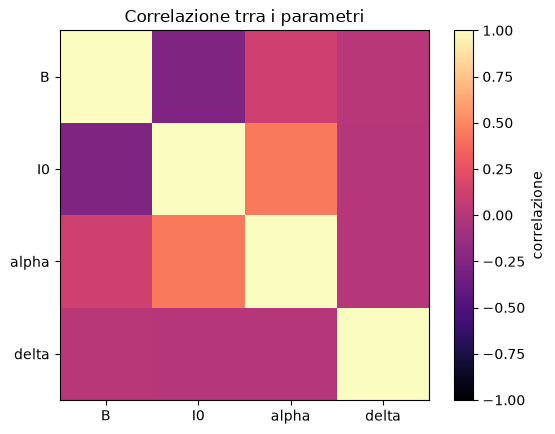

In [21]:
errors=np.sqrt(np.diag(pcov))
correlazione = pcov / np.outer(errors,errors)

par=["B", "I0", "alpha","delta"] 
 
plt.imshow(correlazione,vmin=-1,vmax=1,cmap="magma")
plt.xticks(range(len(par)), par)
plt.yticks(range(len(par)), par)
plt.colorbar(label="correlazione")
plt.title("Correlazione trra i parametri")
plt.show()


P_value:  1.0


IndexError: index 2 is out of bounds for axis 0 with size 2

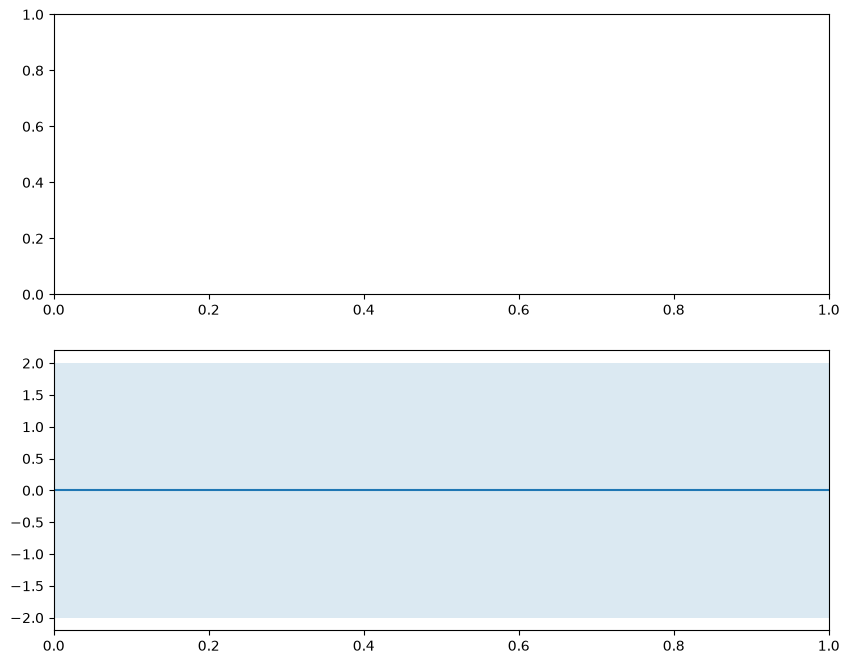

In [26]:

Y=sinusoide(x, B ,I0,alpha, delta)

residui = y - Y

pull  = residui/sigma_y

dof = len(x)-len(par)

chi_2 = np.sum(pull**2)

chi_2_ridotto = chi_2/dof

p_value = chi2.sf(chi_2,dof)

print("P_value: ",p_value)

fig , ax = plt.subplots( 2, 1 , figsize=(10,8))
ax[1].axhline(0 , lw=1.5)
ax[1].axhspan(-2,2,alpha=0.16)
ax[2].plot(x ,  pull ,'.')

